# Calibration from out-of-fold survival predictions

Calibration needs predictions made without fitting on the same subjects. This notebook
fits a Cox model in five stratified folds of the Rossi dataset, pools the held-out
predictions, and examines fixed-time and distributional calibration.

**Do not average fold p-values.** Pool predictions and matching outcomes, then compute
the diagnostic once. Fold training sets overlap, so the usual test p-values on pooled
out-of-fold predictions should be treated as approximate diagnostics rather than as an
independent external-validation test. Keep a separate test set for final validation
after selecting a model with cross-validation.

Run top to bottom with SurvivalEVAL installed. `arrest=1` means an observed arrest;
`arrest=0` means censored follow-up. Times are measured in weeks.

In [1]:
%pip install --quiet lifelines

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines.datasets import load_rossi
from sklearn.model_selection import StratifiedKFold

from SurvivalEVAL import LifelinesEvaluator

plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})

## Build one held-out prediction per subject

Stratification balances the binary event indicator, not the event times. All folds
predict on a common grid of 0–52 weeks. We place each fold's predictions back in the
original row positions and count coverage explicitly, so concatenation cannot silently
mismatch subjects and outcomes. No global feature fitting or tuning is performed here.

In [3]:
data = load_rossi().reset_index(drop=True)
grid = np.arange(53, dtype=float)
out_of_fold = np.full((len(grid), len(data)), np.nan)
coverage = np.zeros(len(data), dtype=int)
fold_id = np.empty(len(data), dtype=int)
fold_summary = []
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (train_index, test_index) in enumerate(folds.split(data, data.arrest), start=1):
    model = CoxPHFitter().fit(data.iloc[train_index], duration_col="week", event_col="arrest")
    held_out = model.predict_survival_function(
        data.iloc[test_index].drop(columns=["week", "arrest"]), times=grid
    )
    assert held_out.columns.tolist() == test_index.tolist()
    out_of_fold[:, test_index] = held_out.to_numpy()
    coverage[test_index] += 1
    fold_id[test_index] = fold
    fold_summary.append({"Fold": fold, "Training subjects": len(train_index),
                         "Held-out subjects": len(test_index),
                         "Held-out events": int(data.arrest.iloc[test_index].sum())})
assert (coverage == 1).all() and np.isfinite(out_of_fold).all()
survival = pd.DataFrame(out_of_fold, index=grid, columns=data.index)
evaluator = LifelinesEvaluator(survival, data.week, data.arrest)
pd.DataFrame(fold_summary).set_index("Fold")

,Training subjects,Held-out subjects,Held-out events
Fold,,,
1,345,87,23
2,345,87,23
3,346,86,23
4,346,86,23
5,346,86,22


## Visualize held-out coverage and predictions

Each row below is scored by one held-out model. The right panel shows one predicted
curve per fold. These are different subjects as well as different fitted models;
differences between curves cannot be attributed to folds alone.

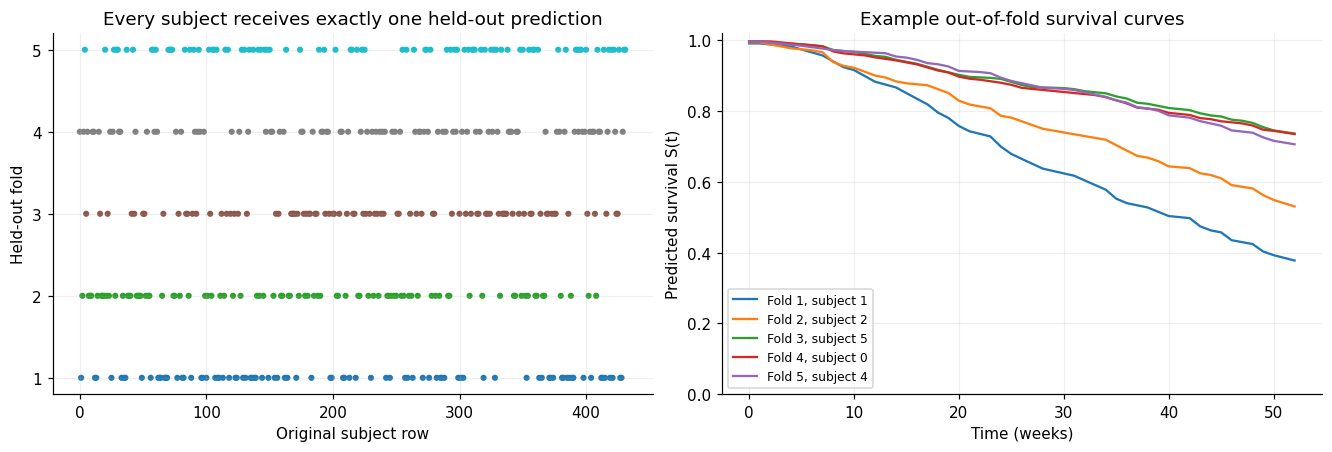

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].scatter(np.arange(len(data)), fold_id, c=fold_id, cmap="tab10", s=9)
axes[0].set(xlabel="Original subject row", ylabel="Held-out fold", yticks=range(1, 6),
            title="Every subject receives exactly one held-out prediction")
for fold in range(1, 6):
    subject = np.flatnonzero(fold_id == fold)[0]
    axes[1].plot(grid, out_of_fold[:, subject], label=f"Fold {fold}, subject {subject}")
axes[1].set(xlabel="Time (weeks)", ylabel="Predicted survival S(t)", ylim=(0, 1.02),
            title="Example out-of-fold survival curves")
axes[1].legend(fontsize=8)
plt.show()

## One-calibration at 26 weeks

Choose the horizon in advance, within follow-up, rather than at the administrative
censoring boundary of 52 weeks. Five equal-sized risk groups provide a coarse summary.
Each group's observed arrest probability is estimated with Kaplan–Meier, accounting
for censoring. A diagonal P–P curve indicates agreement at this horizon.

The Greenwood-adjusted test can have an undefined p-value if a group has zero estimated
variance. Regardless of significance, inspect the size and direction of departures.
A large p-value does not prove calibration.

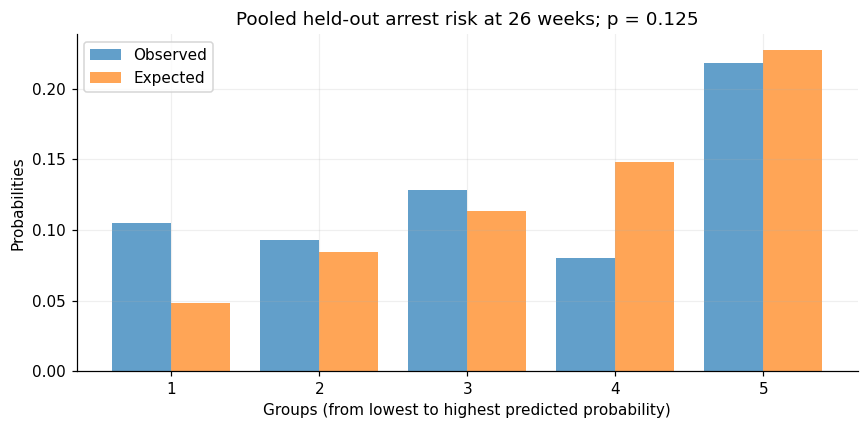

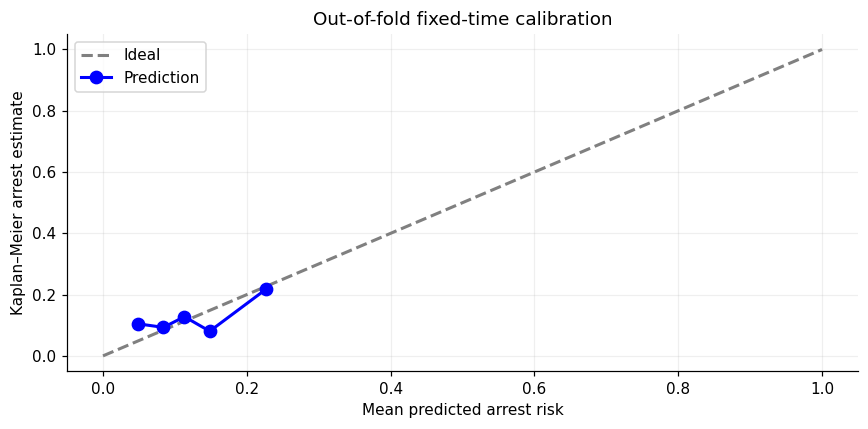

Approximate one-calibration p-value: 0.1255


,Group size,Predicted event risk,Observed event risk
0,87,0.227164,0.218391
1,87,0.148396,0.080460
2,86,0.113253,0.127907
3,86,0.084106,0.093023
4,86,0.048431,0.104651


In [5]:
horizon = 26.0
one_p, details = evaluator.one_calibration(target_time=horizon, num_bins=5, return_details=True)
fig, ax = details["histogram_plot"]
ax.set_title(f"Pooled held-out arrest risk at 26 weeks; p = {one_p:.3g}")
fig.tight_layout()
fig, ax = details["pp_plot"]
ax.set(xlabel="Mean predicted arrest risk", ylabel="Kaplan–Meier arrest estimate",
       title="Out-of-fold fixed-time calibration")
fig.tight_layout()
plt.show()
print(f"Approximate one-calibration p-value: {one_p:.4g}")
pd.DataFrame({"Group size": details["bin_sizes"],
              "Predicted event risk": details["expected_probabilities"],
              "Observed event risk": details["observed_probabilities"]})

## D-calibration across the predicted distributions

D-calibration is not evaluated at a single time. It compares the allocation of subjects
over survival-probability bins with a uniform allocation. Censored subjects contribute
fractional counts over their possible bins. Ten bins are used for this sample size;
increasing the bin count is not automatically more informative.

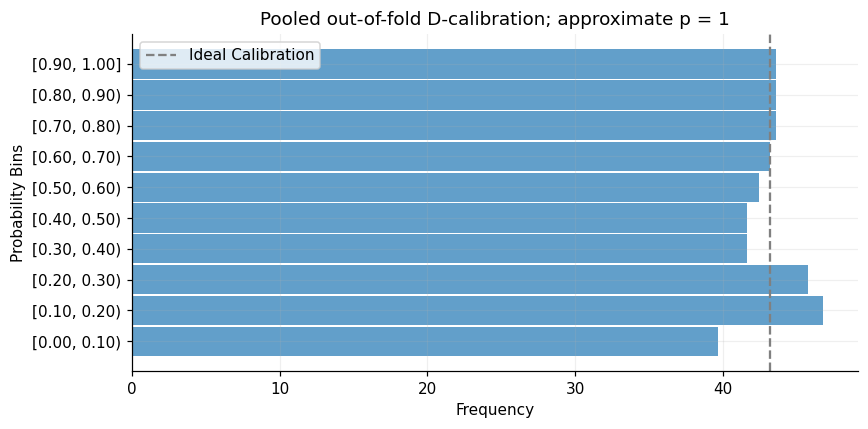

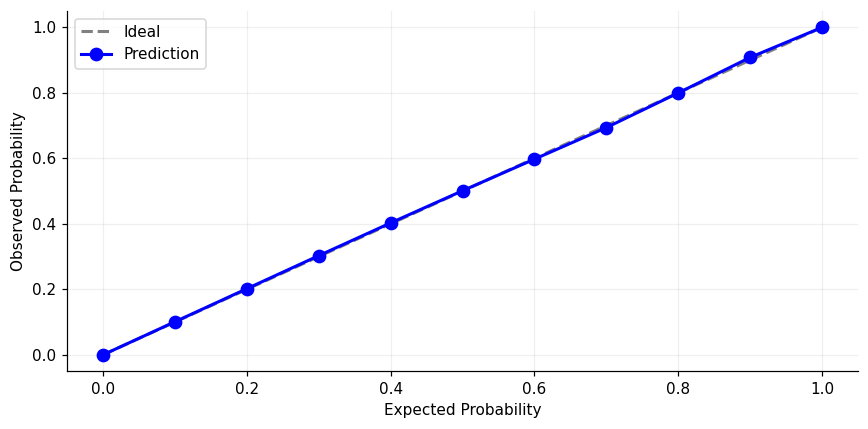

Approximate D-calibration p-value: 0.9997


In [6]:
d_p, details = evaluator.d_calibration(num_bins=10, return_details=True)
fig, ax = details["histogram_plot"]
ax.set_title(f"Pooled out-of-fold D-calibration; approximate p = {d_p:.3g}")
fig.tight_layout()
plt.show()
print(f"Approximate D-calibration p-value: {d_p:.4g}")

Interpret the two diagnostics together: one-calibration concerns a chosen horizon,
while D-calibration concerns the predicted survival distribution. Neither replaces
discrimination or prediction-error assessment. For the distributional diagnostic, see
[Haider et al., Effective Ways to Build and Evaluate Individual Survival Distributions](https://jmlr.org/papers/v21/18-772.html).